# Study 2B: Age Estimation from Truncated Speech (MyST Corpus, 6 seconds)

## Overview

This study uses the same 250 students and the same speech content as Study 2A. The speech is truncated from about 30 seconds to 6 seconds. It runs both audio and text conditions. The purpose is to isolate duration as a factor in age estimation accuracy. It asks whether a model that estimates ages accurately from 30 seconds still does so from 6 seconds of the same speech.

The study ran on the pinned google-genai 2.0.0 setup, so its Gemini estimates are reliable.

## Reference points

- Study 2A used 30 seconds of MyST conversational speech. Gemini estimated 9.2, GPT-4o 8.9, and Nemotron 7.9 from audio.
- Study 2B uses 6 seconds of the same speech from the same students.
- The corrected Kids VA studies used about 6 seconds of speech from younger children aged 5 to 10. Gemini estimated them near 6.7 once the audio reached the model intact.

If the 6 second MyST estimates stay close to the 30 second estimates, duration is not the factor that drives accuracy.

## 1. Setup

In [ ]:
# Environment report. This is an analysis notebook that reads the Study 2B result CSVs.
# It does not call any model, so it reports the versions of the libraries it actually uses
# rather than asserting the data-collection pins. The data were collected under the pinned
# google-genai 2.0.0 environment described in the methods.
import importlib.metadata as ilm

for pkg in ['pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn']:
    try:
        print(f'{pkg}: {ilm.version(pkg)}')
    except ilm.PackageNotFoundError:
        print(f'{pkg}: not installed')

import pandas as pd
import numpy as np
import re
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

## 2. Load Data

In [2]:
df = pd.read_csv('study2b_results_combined.csv')

print(f'Total rows: {len(df):,}')
print(f'Conditions: {df["condition"].value_counts().to_dict()}')
print(f'Models: {df["model"].value_counts().to_dict()}')
print(f'Students: {df["student_id"].nunique()}')

MODELS = {
    'gemini': 'Gemini 2.5 Flash',
    'gpt4o': 'GPT-4o',
    'nemotron': 'Nemotron 3 Nano Omni',
}

Total rows: 13,950
Conditions: {'audio': 7200, 'text': 6750}
Models: {'gpt4o': 4950, 'gemini': 4500, 'nemotron': 4500}
Students: 250


## 3. Diagnostics

In [ ]:
print('RESPONSE DIAGNOSTICS')
print('=' * 70)

for cond in ['audio', 'text']:
    print(f'\n--- {cond.upper()} ---')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        sub = df[(df['model'] == mk) & (df['condition'] == cond)]
        errs = sub[sub['response'].str.startswith('ERROR', na=False)]
        refs = sub[sub['response'].str.contains(
            "sorry|can't estimate|can't determine|can't identify|can't analyze",
            case=False, na=False)]
        ok = sub[~sub.index.isin(errs.index) & ~sub.index.isin(refs.index)]
        print(f'  {MODELS[mk]:.<30s} Errors:{len(errs):>5d}  '
              f'Refusals:{len(refs):>5d}  Answers:{len(ok):>5d}')
        if len(errs) > 0:
            print(f'    Sample error: {errs.iloc[0]["response"][:150]}')
        if len(refs) > 0:
            print(f'    Sample refusal: {refs.iloc[0]["response"][:150]}')

print('\n\nComparison to Study 2 (30s):')
print('  Study 2 audio errors:  Gemini 265, GPT-4o 260, Nemotron 680')
print('  Study 2B audio errors: see above')

## 4. Parse Responses

In [4]:
def parse_yn(r):
    r = str(r)
    if r.startswith('ERROR'): return 'ERROR'
    if re.search(r"sorry|can't", r, re.I): return 'REFUSED'
    u = r.strip().upper()
    if u.startswith('YES'): return 'YES'
    if u.startswith('NO'): return 'NO'
    fl = u.split('\n')[0]
    if 'YES' in fl and 'NO' not in fl: return 'YES'
    if 'NO' in fl and 'YES' not in fl: return 'NO'
    return 'UNCLEAR'

def parse_age(r):
    r = str(r)
    if r.startswith('ERROR'): return None
    if re.search(r"sorry|can't estimate|can't determine|can't identify|can't analyze", r, re.I):
        return None
    m = re.search(r'[Ee]stimated\s+[Aa]ge[:\s]+(\d+)', r)
    if m: return int(m.group(1))
    m = re.search(r'(\d+)\s*-\s*(\d+)\s*years', r)
    if m: return (int(m.group(1)) + int(m.group(2))) / 2
    nums = re.findall(r'\d+', r.split('\n')[0])
    return int(nums[0]) if nums else None

q1 = df[df['question'] == 'q1_over_13'].copy()
q1['pred'] = q1['response'].apply(parse_yn)

q2 = df[df['question'] == 'q2_over_18'].copy()
q2['pred'] = q2['response'].apply(parse_yn)

q3 = df[df['question'] == 'q3_age'].copy()
q3['pred_age'] = q3['response'].apply(parse_age)
valid_q3 = q3.dropna(subset=['pred_age'])

print('Valid Q3:')
for cond in ['audio', 'text']:
    print(f'\n  {cond.upper()}:')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        print(f'    {MODELS[mk]}: {len(s)} from {s["student_id"].nunique()} students')

Valid Q3:

  AUDIO:
    Gemini 2.5 Flash: 750 from 250 students
    GPT-4o: 341 from 90 students
    Nemotron 3 Nano Omni: 747 from 250 students

  TEXT:
    Gemini 2.5 Flash: 741 from 248 students
    GPT-4o: 742 from 250 students
    Nemotron 3 Nano Omni: 744 from 250 students


## 5. Binary Classification (Q1, Q2)

In [5]:
for label, qdf in [("Q1: Over 13? (correct: NO)", q1), ("Q2: Over 18? (correct: NO)", q2)]:
    print(label)
    print('=' * 60)
    print(f'{"Model":<25s} {"Audio % YES":>12s} {"Text % YES":>12s}')
    print('-' * 60)
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        row = f'{MODELS[mk]:<25s}'
        for cond in ['audio', 'text']:
            s = qdf[(qdf['model'] == mk) & (qdf['condition'] == cond)]
            valid = s[s['pred'].isin(['YES', 'NO'])]
            if len(valid) > 0:
                yes_pct = (valid['pred'] == 'YES').mean() * 100
                row += f'{yes_pct:>11.1f}%'
            else:
                row += f'{"n/a":>12s}'
        print(row)
    print()

print('Comparison to Study 2 (30s):')
print('  Q1 audio: Gemini 11.6%, GPT-4o 2.5%, Nemotron 5.0%')
print('  Q1 text:  Gemini 51.9%, GPT-4o 51.7%, Nemotron 1.6%')

Q1: Over 13? (correct: NO)
Model                      Audio % YES   Text % YES
------------------------------------------------------------
Gemini 2.5 Flash                15.5%       73.5%
GPT-4o                          44.0%       12.0%
Nemotron 3 Nano Omni            29.7%        1.2%

Q2: Over 18? (correct: NO)
Model                      Audio % YES   Text % YES
------------------------------------------------------------
Gemini 2.5 Flash                10.9%       52.6%
GPT-4o                          34.2%        1.3%
Nemotron 3 Nano Omni            16.0%        2.3%

Comparison to Study 2 (30s):
  Q1 audio: Gemini 11.6%, GPT-4o 2.5%, Nemotron 5.0%
  Q1 text:  Gemini 51.9%, GPT-4o 51.7%, Nemotron 1.6%


## 6. Age Estimation Overview (Q3)

In [6]:
print('AGE ESTIMATION SUMMARY')
print('Expected range: ~8-11 years (grades 3-5)')
print('=' * 70)
print(f'{"Model":<25s} {"Cond":<7s} {"n_stu":>6s} {"Mean":>6s} {"Med":>5s} '
      f'{"SD":>5s} {"Range":>8s} {"In 8-11":>8s}')
print('-' * 70)

for mk in ['gemini', 'gpt4o', 'nemotron']:
    for cond in ['audio', 'text']:
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        if len(s) == 0:
            print(f'{MODELS[mk]:<25s} {cond:<7s} {"no valid predictions":>40s}')
            continue
        ages = s['pred_age']
        n_stu = s['student_id'].nunique()
        in_range = ((ages >= 8) & (ages <= 11)).mean() * 100
        print(f'{MODELS[mk]:<25s} {cond:<7s} {n_stu:>6d} {ages.mean():>6.1f} '
              f'{ages.median():>5.1f} {ages.std():>5.1f} '
              f'{ages.min():.0f}-{ages.max():.0f}{"":<3s} {in_range:>6.0f}%')

print()
print('Study 2 (30s) for comparison:')
print('  Audio: Gemini 9.2, GPT-4o 8.9, Nemotron 7.9')
print('  Text:  Gemini 11.3, GPT-4o 9.9, Nemotron 14.9')

AGE ESTIMATION SUMMARY
Expected range: ~8-11 years (grades 3-5)
Model                     Cond     n_stu   Mean   Med    SD    Range  In 8-11
----------------------------------------------------------------------
Gemini 2.5 Flash          audio      250    9.0   8.0   3.5 3-42        58%
Gemini 2.5 Flash          text       248   16.2  12.0  10.3 2-75        21%
GPT-4o                    audio       90    9.6   8.0   4.8 5-40        68%
GPT-4o                    text       250   10.6  10.0   6.4 2-40        32%
Nemotron 3 Nano Omni      audio      250   11.6   6.0  11.0 2-75        15%
Nemotron 3 Nano Omni      text       250   22.4  22.0  12.8 0-150         8%

Study 2 (30s) for comparison:
  Audio: Gemini 9.2, GPT-4o 8.9, Nemotron 7.9
  Text:  Gemini 11.3, GPT-4o 9.9, Nemotron 14.9


## 7. Audio vs. Text Comparison

In [7]:
student_means = valid_q3.groupby(['student_id', 'model', 'condition'])['pred_age'].mean().reset_index()

print('AUDIO vs. TEXT DELTA')
print('=' * 70)

deltas = {}

for mk in ['gemini', 'gpt4o', 'nemotron']:
    audio_m = student_means[(student_means['model'] == mk) & (student_means['condition'] == 'audio')]
    text_m = student_means[(student_means['model'] == mk) & (student_means['condition'] == 'text')]
    merged = audio_m[['student_id', 'pred_age']].merge(
        text_m[['student_id', 'pred_age']], on='student_id', suffixes=('_audio', '_text'))
    merged['delta'] = merged['pred_age_audio'] - merged['pred_age_text']
    deltas[mk] = merged

    if len(merged) < 3:
        print(f'\n{MODELS[mk]}: insufficient paired data ({len(merged)} students)')
        continue

    t, p = stats.ttest_1samp(merged['delta'], 0)
    sig = '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'n.s.'

    print(f'\n{MODELS[mk]} ({len(merged)} students):')
    print(f'  Audio mean: {merged["pred_age_audio"].mean():.1f}')
    print(f'  Text mean:  {merged["pred_age_text"].mean():.1f}')
    print(f'  Delta:      {merged["delta"].mean():+.1f} years')
    print(f'  t={t:.2f}, p={p:.6f} {sig}')

print('\nStudy 2 (30s) deltas: Gemini -2.2, GPT-4o -1.0, Nemotron -7.0')

AUDIO vs. TEXT DELTA

Gemini 2.5 Flash (248 students):
  Audio mean: 9.0
  Text mean:  16.2
  Delta:      -7.1 years
  t=-12.99, p=0.000000 ***

GPT-4o (90 students):
  Audio mean: 10.1
  Text mean:  10.4
  Delta:      -0.4 years
  t=-0.56, p=0.575500 n.s.

Nemotron 3 Nano Omni (250 students):
  Audio mean: 11.6
  Text mean:  22.4
  Delta:      -10.8 years
  t=-12.29, p=0.000000 ***

Study 2 (30s) deltas: Gemini -2.2, GPT-4o -1.0, Nemotron -7.0


## 8. The Duration Test: Study 2 vs. Study 2B

This is the key comparison. Same students, same speech content, 30s vs. 6s.

In [8]:
print('DURATION COMPARISON: 30s (Study 2) vs. 6s (Study 2B)')
print('=' * 70)
print()
print(f'{"Model":<25s} {"Metric":<15s} {"30s":>8s} {"6s":>8s} {"Change":>10s}')
print('-' * 70)

# Study 2 reference values (from earlier analysis)
study2_ref = {
    'gemini': {'audio_mean': 9.2, 'text_mean': 11.3, 'q1_audio': 11.6, 'q1_text': 51.9},
    'gpt4o': {'audio_mean': 8.9, 'text_mean': 9.9, 'q1_audio': 2.5, 'q1_text': 51.7},
    'nemotron': {'audio_mean': 7.9, 'text_mean': 14.9, 'q1_audio': 5.0, 'q1_text': 1.6},
}

for mk in ['gemini', 'gpt4o', 'nemotron']:
    ref = study2_ref[mk]

    # Audio mean
    s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == 'audio')]
    audio_6s = s['pred_age'].mean() if len(s) > 0 else float('nan')
    change = audio_6s - ref['audio_mean']
    print(f'{MODELS[mk]:<25s} {"Audio mean":<15s} {ref["audio_mean"]:>8.1f} {audio_6s:>8.1f} {change:>+10.1f}')

    # Text mean
    s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == 'text')]
    text_6s = s['pred_age'].mean() if len(s) > 0 else float('nan')
    change = text_6s - ref['text_mean']
    print(f'{"":25s} {"Text mean":<15s} {ref["text_mean"]:>8.1f} {text_6s:>8.1f} {change:>+10.1f}')

    # Q1 audio
    s = q1[(q1['model'] == mk) & (q1['condition'] == 'audio')]
    valid = s[s['pred'].isin(['YES', 'NO'])]
    q1_6s = (valid['pred'] == 'YES').mean() * 100 if len(valid) > 0 else float('nan')
    change = q1_6s - ref['q1_audio']
    print(f'{"":25s} {"Q1 audio %YES":<15s} {ref["q1_audio"]:>7.1f}% {q1_6s:>7.1f}% {change:>+9.1f}%')

    print()

DURATION COMPARISON: 30s (Study 2) vs. 6s (Study 2B)

Model                     Metric               30s       6s     Change
----------------------------------------------------------------------
Gemini 2.5 Flash          Audio mean           9.2      9.0       -0.2
                          Text mean           11.3     16.2       +4.9
                          Q1 audio %YES      11.6%    15.5%      +3.9%

GPT-4o                    Audio mean           8.9      9.6       +0.7
                          Text mean            9.9     10.6       +0.7
                          Q1 audio %YES       2.5%    44.0%     +41.5%

Nemotron 3 Nano Omni      Audio mean           7.9     11.6       +3.7
                          Text mean           14.9     22.4       +7.5
                          Q1 audio %YES       5.0%    29.7%     +24.7%



## 9. Visualization

### 9a. Age distributions by model and condition

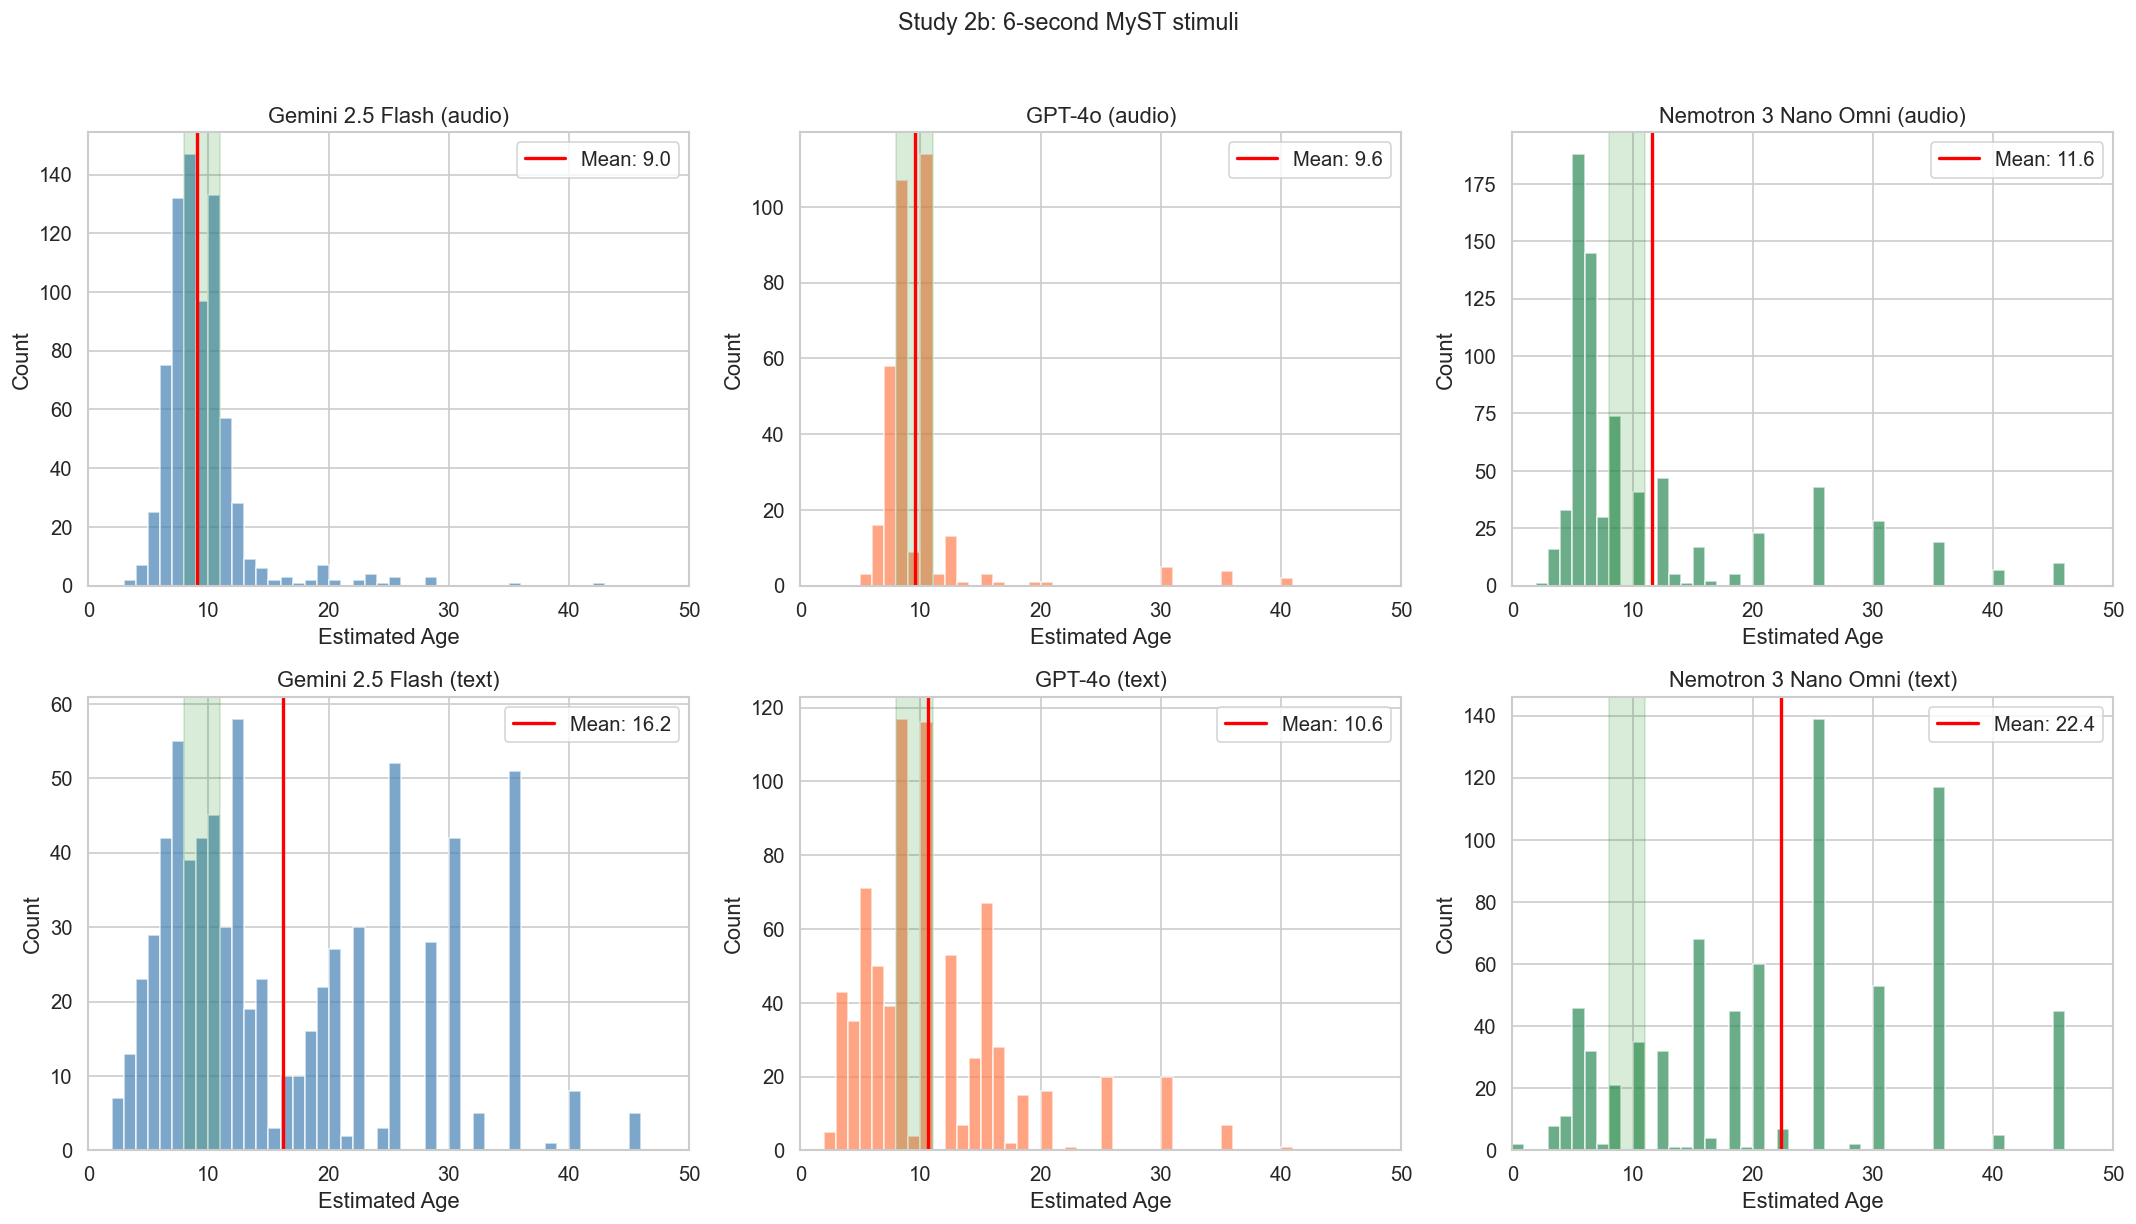

In [9]:
colors = {'gemini': 'steelblue', 'gpt4o': 'coral', 'nemotron': 'seagreen'}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, mk in enumerate(['gemini', 'gpt4o', 'nemotron']):
    for j, cond in enumerate(['audio', 'text']):
        ax = axes[j][i]
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        if len(s) > 0:
            ax.hist(s['pred_age'], bins=range(0, 50, 1), color=colors[mk],
                    alpha=0.7, edgecolor='white')
            ax.axvspan(8, 11, alpha=0.15, color='green')
            ax.axvline(s['pred_age'].mean(), color='red', linestyle='-', lw=2,
                      label=f'Mean: {s["pred_age"].mean():.1f}')
            ax.legend()
        ax.set_xlabel('Estimated Age')
        ax.set_ylabel('Count')
        ax.set_title(f'{MODELS[mk]} ({cond})')
        ax.set_xlim(0, 50)

plt.suptitle('Study 2B: 6-second MyST stimuli', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('study2b_age_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

### 9b. Duration comparison (30s vs 6s)

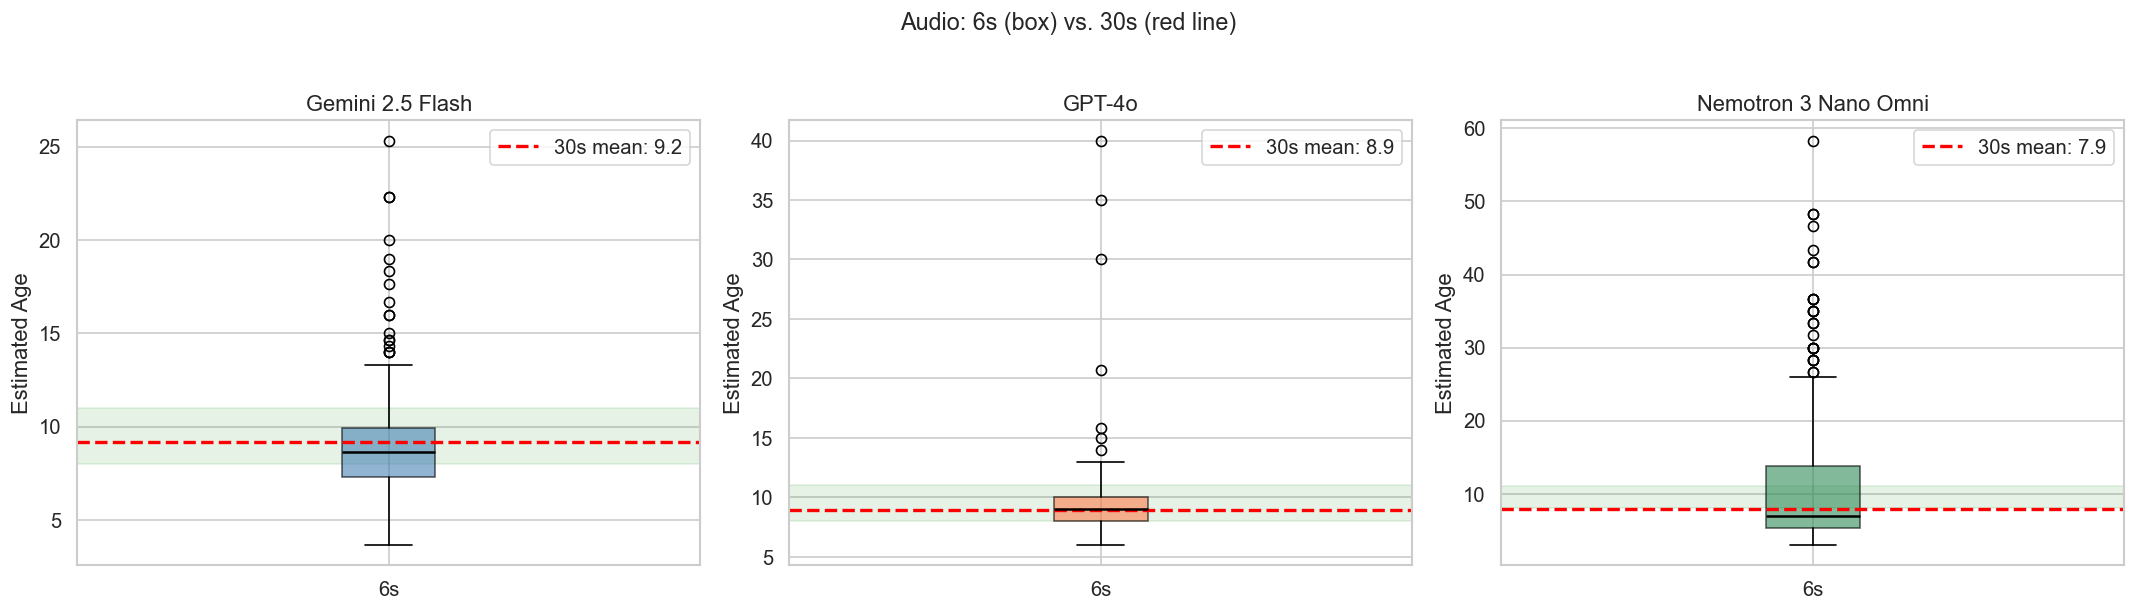

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

study2_audio_means = {'gemini': 9.2, 'gpt4o': 8.9, 'nemotron': 7.9}

for i, mk in enumerate(['gemini', 'gpt4o', 'nemotron']):
    ax = axes[i]
    s_6s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == 'audio')]

    data = []
    labels = []

    if len(s_6s) > 0:
        sm = s_6s.groupby('student_id')['pred_age'].mean()
        data.append(sm.values)
        labels.append('6s')

    # We don't have Study 2 raw data here, but show reference line
    bp = ax.boxplot(data, labels=labels, patch_artist=True,
                     medianprops={'color': 'black', 'linewidth': 1.5})
    for patch in bp['boxes']:
        patch.set_facecolor(colors[mk])
        patch.set_alpha(0.6)

    ax.axhline(y=study2_audio_means[mk], color='red', linestyle='--', lw=2,
              label=f'30s mean: {study2_audio_means[mk]}')
    ax.axhspan(8, 11, alpha=0.1, color='green')
    ax.set_ylabel('Estimated Age')
    ax.set_title(MODELS[mk])
    ax.legend()

plt.suptitle('Audio: 6s (box) vs. 30s (red line)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('study2b_duration_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### 9c. Binary classification comparison

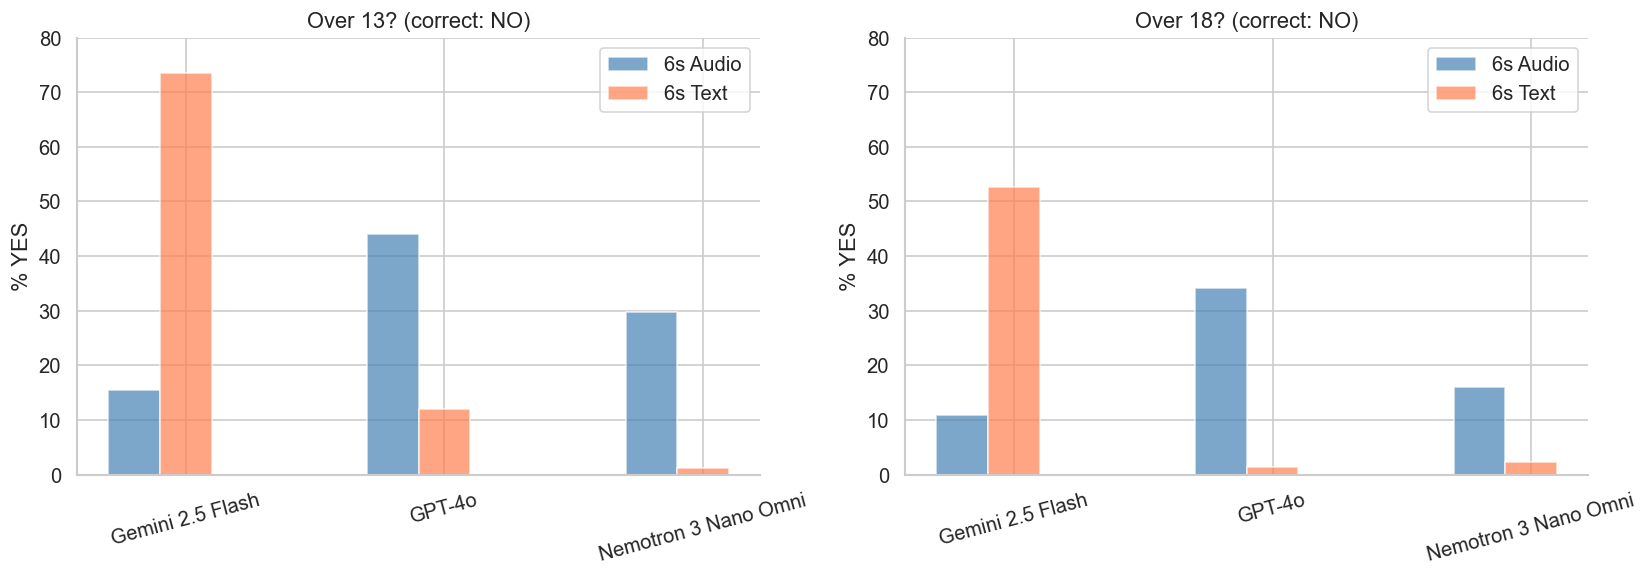

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
model_order = ['gemini', 'gpt4o', 'nemotron']
x = np.arange(len(model_order))
width = 0.2

study2_q1 = {'gemini': 11.6, 'gpt4o': 2.5, 'nemotron': 5.0}

for idx, (label, qdf) in enumerate([("Over 13?", q1), ("Over 18?", q2)]):
    ax = axes[idx]

    audio_6s = []
    text_6s = []
    audio_30s = []

    for mk in model_order:
        # 6s audio
        s = qdf[(qdf['model'] == mk) & (qdf['condition'] == 'audio')]
        valid = s[s['pred'].isin(['YES', 'NO'])]
        audio_6s.append((valid['pred'] == 'YES').mean() * 100 if len(valid) > 0 else 0)

        # 6s text
        s = qdf[(qdf['model'] == mk) & (qdf['condition'] == 'text')]
        valid = s[s['pred'].isin(['YES', 'NO'])]
        text_6s.append((valid['pred'] == 'YES').mean() * 100 if len(valid) > 0 else 0)

    ax.bar(x - width, audio_6s, width, label='6s Audio', color='steelblue', alpha=0.7)
    ax.bar(x, text_6s, width, label='6s Text', color='coral', alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([MODELS[mk] for mk in model_order], rotation=15)
    ax.set_ylabel('% YES')
    ax.set_title(f'{label} (correct: NO)')
    ax.legend()
    ax.set_ylim(0, 80)

sns.despine()
plt.tight_layout()
plt.savefig('study2b_binary_classification.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Sample Reasoning

In [ ]:
for cond in ['audio', 'text']:
    print(f'\n{"=" * 60}')
    print(f'{cond.upper()} CONDITION')
    print(f'{"=" * 60}')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        s = q3[(q3['model'] == mk) & (q3['condition'] == cond)]
        answered = s[s['pred_age'].notna()]
        if len(answered) > 0:
            row = answered.iloc[0]
            print(f'\n  {MODELS[mk]} [{row["student_id"]}]:')
            print(f'  {row["response"][:300]}')
        else:
            refused = s[s['response'].str.contains("sorry|can't", case=False, na=False)]
            if len(refused) > 0:
                print(f'\n  {MODELS[mk]} [REFUSED]: {refused.iloc[0]["response"][:200]}')
            else:
                errored = s[s['response'].str.startswith('ERROR')]
                if len(errored) > 0:
                    print(f'\n  {MODELS[mk]} [ERROR]: {errored.iloc[0]["response"][:200]}')

## 11. Save

In [13]:
valid_q3.to_csv('study2b_q3_parsed.csv', index=False)
student_means.to_csv('study2b_student_means.csv', index=False)
print('Saved: study2b_q3_parsed.csv, study2b_student_means.csv')

Saved: study2b_q3_parsed.csv, study2b_student_means.csv


## 12. Interpretation

### Duration matters, but not equally for all models

The core finding is that truncating MyST stimuli from 30 seconds to 6 seconds degrades performance for some models and not others. The severity depends on the model and the modality.

Gemini's audio estimates were barely affected. The mean estimate moved from 9.2 at 30 seconds to 9.0 at 6 seconds. The over 13 error rate rose only modestly from 11.6 percent to 15.5 percent. Gemini identifies these children as children from just 6 seconds of conversational speech. This matches its corrected performance on the Kids VA corpus. There it estimates 5 to 10 year olds near 6.7 from clips of similar length. Duration is not what drives accuracy.

Nemotron degraded substantially. Its audio mean rose from 7.9 to 11.6, and its over 13 audio error rate jumped from 5.0 percent to 29.7 percent. Nemotron benefits from longer audio and loses accuracy at shorter durations.

GPT-4o is difficult to evaluate here. Rate limiting prevented 52 percent of audio calls from completing. That left only 90 of 250 students with valid responses. Among those the mean estimate of 9.6 was close to the Study 2A value of 8.9, but the over 13 error rate jumped to 44.0 percent. Whether that reflects genuine degradation or a non-representative subsample is unclear. The rate limiting is itself a practical finding. The preview model's infrastructure constraints made large scale audio studies impractical at the time of testing in May 2026.

### Text degradation is steeper than audio

Reducing the transcript from about 30 seconds' worth to about 6 seconds' worth produced large increases in overestimation. Gemini's text mean jumped from 11.3 to 16.2. Nemotron's rose from 14.9 to 22.4. The audio minus text gap widened accordingly. For Gemini it went from -2.2 to -7.1. For Nemotron it went from -7.0 to -10.8. Both differences were significant at p below .0001. With less text the models default to older estimates, and the acoustic signal becomes even more important as a corrective.

Gemini's text over 13 error rate jumped from 51.9 percent to 73.5 percent. From a short transcript of child speech, Gemini classified nearly three quarters of these 8 to 11 year olds as over 13. This reinforces the Study 2A finding that text based age verification is unreliable for children in this range, and shorter text makes it worse.

### Regulatory implications

At 6 seconds no model reaches acceptable accuracy on the over 13 question for audio. Gemini at 15.5 percent is the best of the three but would still misclassify roughly one in six children. Nemotron at 29.7 percent would misclassify nearly a third. These rates are worse than at 30 seconds, where Gemini was 11.6 percent and Nemotron 5.0 percent. Any audio based age verification system would need a minimum amount of speech to function reliably.

### No corpus divergence once the audio reaches the model

An earlier version of this analysis treated Gemini's Kids VA estimate near 35 as a corpus specific failure and called it a puzzle. That estimate was an artifact. The original Kids VA run used an older google-genai version that double encoded the audio, so Gemini was estimating from corrupted input and returning adult ages. Once the defect was fixed, Gemini estimated the Kids VA children accurately. The table below uses the corrected figures.

| Study | Duration | Corpus | Gemini audio mean |
|-------|----------|--------|-------------------|
| Study 1A | 6s | Kids VA scripted | ~6.7 |
| Study 2B | 6s | MyST conversational | 9.0 |
| Study 2A | 30s | MyST conversational | 9.2 |

Gemini estimates children accurately at 6 seconds on both corpora. Duration does not drive accuracy, since 6 second MyST is as accurate as 30 second MyST. Speech type does not drive it either, since corrected Kids VA is accurate for both scripted and spontaneous speech. There is no corpus divergence left to explain. The earlier divergence was a software defect, and only Gemini was affected, since the other two models used different SDKs.

### Caveats

GPT-4o audio results are based on 90 of 250 students because of rate limiting and may not be representative. The truncated text transcripts are approximate. They are taken as the first fifth of the words and may not correspond exactly to the first 6 seconds of audio. As with all studies in this project, we cannot fully separate model capability from alignment policy from recording artifacts.